# E4. Tinh chỉnh siêu tham số

Đây là bước Hyperparameter tuning của ML pipeline (Bài 09). Nhóm so sánh Grid Search, Random Search và Bayesian
Optimization (Optuna với bộ lấy mẫu TPE) với cùng số lần thử, trên model đã chọn ở E3 (LightGBM, 21 cột gốc).

> **Trong cuộc thi.** Nhóm gần như không dò tham số cho model đơn. LightGBM giữ cấu hình phổ biến, chỉ đổi learning
> rate từ 0,05 xuống 0,02 (+5×10⁻⁵, E2). Phần tinh chỉnh chủ yếu dành cho stacker (meta model của stacking) và cho
> Q-FT:
>
> | Ngày | Tinh chỉnh | Cách dò | Kết quả | Quyết định |
> | --- | --- | --- | --- | --- |
> | 15/10 | C của Logistic Regression `A_lr`: 0,01 / 0,05 / 0,2 | lưới | C = 0,05 tốt nhất | dùng C = 0,05 |
> | 16/10 | stacker: bỏ member gần trùng (tương quan > 0,999); stacker riêng theo `Type of Travel` (bản v3) | 3 meta seed | đều âm (theo `Type of Travel`: −7×10⁻⁶ đến −1×10⁻⁵) | bỏ cả hai |
> | 16/10 | stacker: 6 mức C của LR × 3 cấu hình LightGBM × tỉ lệ trộn 0–0,4 (bản v5) | lưới, 3 meta seed | mọi cấu hình trong ±1×10⁻⁶ so với nền | giữ nền |
> | 18/10 | ngưỡng cắt logit ±9,2 / ±13,8 / ±20,7 (bản v8) | lưới, 3 seed | ±0,2×10⁻⁶; riêng ±9,2 giảm 2×10⁻⁶ | không ảnh hưởng |
> | 20/10 | FWLS, tức hệ số của stacker thay đổi theo nhóm khách (bản v13) | lưới 3 mức, 3 seed | tốt nhất +1,8×10⁻⁶ đến +3,5×10⁻⁶ | dưới cổng, dừng tối ưu stacker |
> | 22/10 | hệ số nhân theo họ model trong LR (TabPFN 2/3/4,5; foundation model khác 1/1,5/2,5; MLP 0,7/1/1,5; bản v16) | lưới 27 điểm, 3 seed | tốt nhất +0,5×10⁻⁶ đến +1,4×10⁻⁶ | dưới cổng |
> | 22/10 | tỉ trọng LightGBM trong stacker, W từ 0 đến 0,4 (bản v15) | lưới, 3 seed | W = 0,2 tốt nhất; bỏ hẳn LightGBM giảm 1,1×10⁻⁵ đến 1,7×10⁻⁵ (14/15 fold) | giữ W = 0,2 |
> | 25/10 | số epoch fine-tune của Q-FT, 2 hay 4 (Q-FT v3) | thử trực tiếp | thấp hơn ở 5/5 fold | giữ 2 epoch |
> | 25/10 | hệ số của Q-FT trong stacker ×1 / ×1,5, một seed hay trung bình 2 seed (bản v17) | lưới, 3 seed | ×1,5 với seed 42: +6×10⁻⁶ đến +8×10⁻⁶, 14/15 fold | qua cổng, dùng cho bài nộp |
>
> "Cổng" là ngưỡng giữ thay đổi của nhóm (E0): tăng ít nhất 5×10⁻⁶ ở cả 3 meta seed. Phần lớn các lần dò không qua
> cổng. Khi mọi cấu hình chỉ chênh nhau vài phần triệu, cấu hình "tốt nhất" nhiều khả năng chỉ tốt hơn nhờ nhiễu.

Thí nghiệm dưới đây xét câu hỏi tương tự trên một model đơn, nơi tham số có ảnh hưởng rõ hơn.

Nội dung:
1. Thiết kế: không gian tham số, ngân sách, cách chấm
2. Đường hội tụ: điểm tốt nhất sau mỗi lần thử
3. Đánh giá lại trên 5 fold: lợi ích thật và độ lạc quan của fold dùng để dò
4. Tham số nào quan trọng
5. Tóm tắt và quyết định

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from config import RESULTS_DIR
import plot as P

pd.set_option("display.width", 200)
KDIR = RESULTS_DIR / "E4_tuning"  # output kernel thanhmn123/cs116-e4-tuning (exp/kaggle/E4_tuning.py)
trials = pd.read_csv(KDIR / "E4_trials.csv")
final = pd.read_csv(KDIR / "E4_final.csv")
PARAMS = ["num_leaves", "min_child_samples", "colsample_bytree", "subsample", "reg_lambda"]
RUN = {("grid", 0): "Grid", ("random", 0): "Random (seed 0)", ("random", 1): "Random (seed 1)",
       ("optuna", 0): "Optuna TPE (seed 0)", ("optuna", 1): "Optuna TPE (seed 1)"}
COLOR = {"grid": P.INK_3, "random": P.ORANGE, "optuna": P.BLUE}

## 1. Thiết kế

| | Grid Search | Random Search | Optuna TPE |
| --- | --- | --- | --- |
| Ngân sách | 24 lần thử | 24 lần thử | 24 lần thử (8 lần đầu ngẫu nhiên) |
| Tham số dò | 3: `num_leaves` {31, 63, 127, 255} × `min_child_samples` {10, 50, 200} × `colsample_bytree` {0,5; 0,8} | 5: thêm `subsample` [0,5; 1], `reg_lambda` [10⁻³; 30] (thang log) | như Random |
| Số lần chạy | 1 (lưới cố định) | 2 seed | 2 seed |

- Mỗi lần thử train LightGBM với learning rate 0,1, early stopping trên 10% tách từ phần train của fold 0, và chấm
  AUC trên validation của fold 0. `num_leaves` và `min_child_samples` được dò theo thang log.
- Cấu hình tốt nhất của mỗi lần chạy, cùng cấu hình mặc định của E3, được chạy lại đủ 5 fold. Vì fold 0 đã dùng để
  chọn cấu hình nên điểm trên fold 0 lạc quan; điểm dùng để so sánh là trung bình fold 1–4.
- Tổng cộng 120 lần thử và 30 lần fit cuối, chạy 34 phút trên Kaggle (CPU 4 luồng).

In [2]:
trials["run"] = [RUN[(m, s)] for m, s in zip(trials["method"], trials["seed"])]
summary = trials.groupby("run", sort=False).agg(
    best_fold0=("val_auc_fold0", "max"), mean_fold0=("val_auc_fold0", "mean"), worst_fold0=("val_auc_fold0", "min"),
    trees_mean=("trees", "mean"), minutes=("seconds", lambda s: round(s.sum() / 60, 1)))
summary.round(6)

,best_fold0,mean_fold0,worst_fold0,trees_mean,minutes
run,,,,,
Grid,0.958915,0.958646,0.958388,251.416667,5.4
Random (seed 0),0.958996,0.958649,0.958213,225.375000,5.1
Optuna TPE (seed 0),0.959186,0.958849,0.958320,193.666667,5.1
Random (seed 1),0.959004,0.958697,0.958343,339.583333,6.4
Optuna TPE (seed 1),0.959226,0.958901,0.958278,259.541667,5.9


## 2. Đường hội tụ

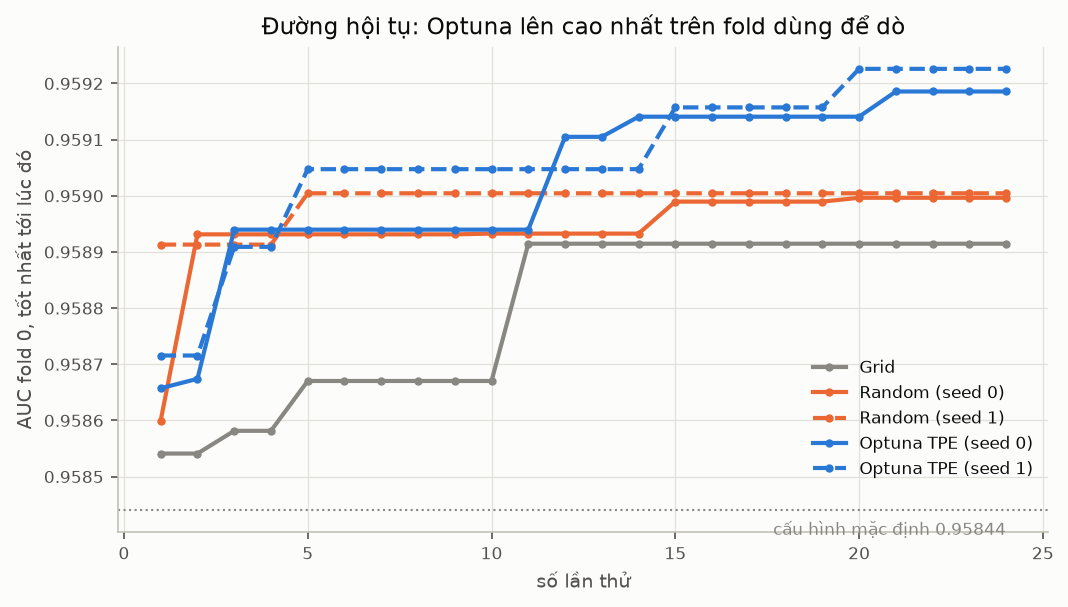

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for (m, s), name in RUN.items():
    t = trials[(trials["method"] == m) & (trials["seed"] == s)].sort_values("trial")
    ax.plot(t["trial"] + 1, t["val_auc_fold0"].cummax(), color=COLOR[m], ls="-" if s == 0 else "--",
            marker="o", markersize=3, label=name)
default_f0 = final.set_index("config").loc["default", "fold0_tuned"]
ax.axhline(default_f0, color=P.REF, lw=1, ls=":")
ax.annotate(f"cấu hình mặc định {default_f0:.5f}", (24, default_f0), textcoords="offset points", xytext=(0, -12),
            ha="right", fontsize=8, color=P.INK_3)
ax.set_xlabel("số lần thử")
ax.set_ylabel("AUC fold 0, tốt nhất tới lúc đó")
ax.set_title("Đường hội tụ: Optuna lên cao nhất trên fold dùng để dò")
ax.legend(loc="lower right", bbox_to_anchor=(1, 0.08))
P.save(fig, "E4_01_convergence")

**Nhận xét mục 2**
- Trên fold dùng để dò, Optuna cho kết quả cao nhất ở cả 2 seed (0,95919 và 0,95923), tiếp theo là Random (0,95900)
  và Grid (0,95892). AUC trung bình của các lần thử Optuna (0,95885–0,95890) cũng cao hơn Random và Grid
  (0,95865–0,95870), phù hợp với cách TPE hoạt động: sau 8 lần thử ngẫu nhiên, nó lấy mẫu tập trung hơn ở vùng có
  điểm cao.
- Grid chỉ dò được 3 tham số ở các giá trị cho sẵn, còn Random và Optuna với cùng 24 lần thử dò được cả 5 tham số.
  Đây cũng là lý do Bài 09 và Bergstra & Bengio (2012) khuyên dùng Random Search thay cho Grid Search khi có nhiều
  tham số.

## 3. Đánh giá lại trên 5 fold

In [4]:
f = final.copy()
f["tên"] = f["config"].map({"default": "mặc định (E3)", "grid": "Grid", "random_s0": "Random (seed 0)",
                            "random_s1": "Random (seed 1)", "optuna_s0": "Optuna TPE (seed 0)",
                            "optuna_s1": "Optuna TPE (seed 1)"})
base = f.set_index("config").loc["default"]
fold_cols = [f"fold_{k}" for k in range(5)]
f["Δ fold 1–4 so với mặc định"] = f["folds1_4_mean"] - base["folds1_4_mean"]
f["fold tăng (1–4)"] = [int((r[fold_cols[1:]].values > base[fold_cols[1:]].values).sum()) for _, r in f.iterrows()]
f["lạc quan fold 0"] = f["fold0_tuned"] - f["folds1_4_mean"]
f["lạc quan do chọn"] = f["lạc quan fold 0"] - (base["fold0_tuned"] - base["folds1_4_mean"])
f.to_csv(RESULTS_DIR / "E4_summary.csv", index=False)
show = f[["tên", "cv_auc", "fold0_tuned", "folds1_4_mean", "Δ fold 1–4 so với mặc định", "fold tăng (1–4)",
          "lạc quan do chọn", "trees_mean"]]
show.round(6)

,tên,cv_auc,fold0_tuned,folds1_4_mean,Δ fold 1–4 so với mặc định,fold tăng (1–4),lạc quan do chọn,trees_mean
0,mặc định (E3),0.958358,0.958441,0.958347,0.000000,0,0.000000,165.6
1,Grid,0.958674,0.958915,0.958627,0.000279,3,0.000194,227.2
2,Random (seed 0),0.958626,0.958996,0.958543,0.000196,4,0.000360,98.2
3,Optuna TPE (seed 0),0.958891,0.959186,0.958825,0.000478,4,0.000267,261.0
4,Random (seed 1),0.958930,0.959004,0.958920,0.000573,4,-0.000009,176.8
5,Optuna TPE (seed 1),0.958832,0.959226,0.958742,0.000395,4,0.000390,150.2


In [5]:
print("Cấu hình tốt nhất của mỗi lần chạy:")
for _, r in f.iterrows():
    p = json.loads(r["params"])
    print(f"  {r['tên']:22s}", ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}" for k, v in p.items()))

Cấu hình tốt nhất của mỗi lần chạy:
  mặc định (E3)          num_leaves=63, min_child_samples=20, colsample_bytree=0.8, subsample=0.8, reg_lambda=0
  Grid                   num_leaves=63, min_child_samples=200, colsample_bytree=0.5, subsample=0.8, reg_lambda=0
  Random (seed 0)        num_leaves=225, min_child_samples=9, colsample_bytree=0.984, subsample=0.945, reg_lambda=4.81
  Optuna TPE (seed 0)    num_leaves=88, min_child_samples=15, colsample_bytree=0.571, subsample=0.89, reg_lambda=26
  Random (seed 1)        num_leaves=125, min_child_samples=15, colsample_bytree=0.691, subsample=0.99, reg_lambda=20.2
  Optuna TPE (seed 1)    num_leaves=187, min_child_samples=138, colsample_bytree=0.525, subsample=0.966, reg_lambda=18.8


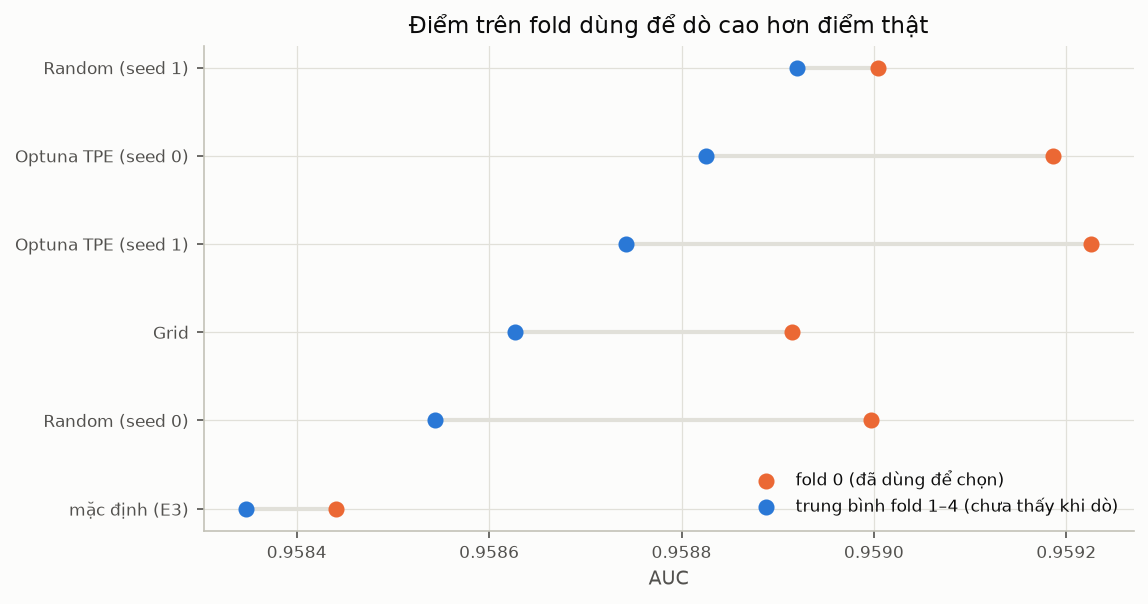

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
order = f.sort_values("folds1_4_mean")
y = np.arange(len(order))
ax.scatter(order["fold0_tuned"], y, color=P.ORANGE, s=45, label="fold 0 (đã dùng để chọn)", zorder=3)
ax.scatter(order["folds1_4_mean"], y, color=P.BLUE, s=45, label="trung bình fold 1–4 (chưa thấy khi dò)", zorder=3)
for yi, (a, b) in enumerate(zip(order["fold0_tuned"], order["folds1_4_mean"])):
    ax.plot([a, b], [yi, yi], color=P.GRID, lw=2, zorder=1)
ax.set_yticks(y, order["tên"])
ax.set_xlabel("AUC")
ax.set_title("Điểm trên fold dùng để dò cao hơn điểm thật")
ax.legend(loc="lower right")
P.save(fig, "E4_02_optimism")

**Nhận xét mục 3**
- Tinh chỉnh có tác dụng. Mọi cấu hình dò được đều cao hơn cấu hình mặc định trên fold 1–4, từ 2×10⁻⁴ (Random seed 0)
  đến 6×10⁻⁴ (Random seed 1), và tăng ở 3–4 trên 4 fold. Mức này lớn hơn chênh lệch giữa các thư viện boosting ở E3
  (4×10⁻⁵).
- Thứ hạng thay đổi khi chấm trên fold chưa dùng để dò. Optuna cao hơn Random trên fold 0, nhưng trên fold 1–4 cấu
  hình tốt nhất lại là Random seed 1. Chênh lệch giữa hai seed của cùng một phương pháp (Random: 0,95854 và 0,95892)
  lớn hơn chênh lệch giữa các phương pháp, nên với 24 lần thử chưa thể kết luận Optuna tốt hơn Random trên bài này.
- **Điểm trên fold dùng để dò bị lạc quan.** Với cấu hình mặc định, fold 0 vốn cao hơn trung bình fold 1–4 khoảng
  1×10⁻⁴. Với các cấu hình đã dò, khoảng cách này tăng thêm 2×10⁻⁴ đến 4×10⁻⁴ (cột "lạc quan do chọn"; riêng Random
  seed 1 gần 0). Lý do là khi chọn cấu hình tốt nhất trong 24 lần thử trên cùng một tập, nhóm chọn luôn cả phần nhiễu
  có lợi của tập đó. Đây là cùng một vấn đề với rò rỉ ở E0: tập đã dùng để ra quyết định không còn là tập đánh giá độc
  lập. Vì vậy CV 5 fold có chứa fold 0 cũng lạc quan khoảng 1×10⁻⁴.
- Cả 5 cấu hình tốt nhất đều có `reg_lambda` lớn (5–26) hoặc `colsample_bytree` thấp (0,5–0,7), tức regularization
  mạnh hơn mặc định (`reg_lambda` = 0). Bốn cấu hình dò 5 tham số đều có nhiều lá hơn mặc định (88–225 so với 63).

## 4. Tham số nào quan trọng
Tương quan Spearman giữa giá trị tham số và AUC fold 0 trên 96 lần thử của Random và Optuna (không dùng Grid vì giá
trị cố định). Đây chỉ là ước lượng thô, vì Optuna lấy mẫu dày ở vùng điểm cao nên các lần thử không độc lập.

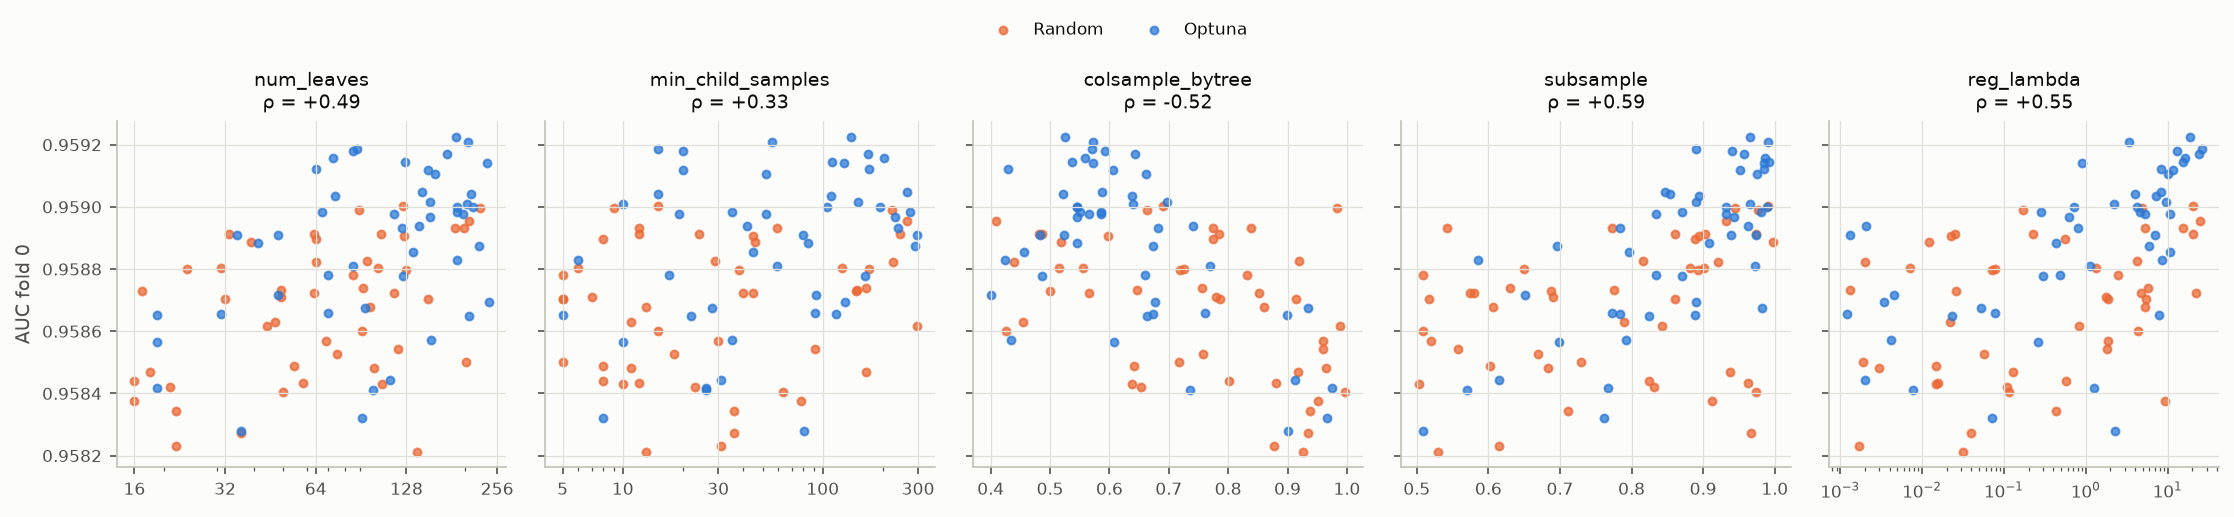

,spearman,spearman (chỉ Random)
tham số,,
num_leaves,0.493,0.407
min_child_samples,0.329,0.168
colsample_bytree,-0.519,-0.432
subsample,0.588,0.321
reg_lambda,0.552,0.332


In [7]:
rt = trials[trials["method"] != "grid"]
imp = pd.DataFrame([{"tham số": p, "spearman": spearmanr(rt[p], rt["val_auc_fold0"]).statistic,
                     "spearman (chỉ Random)": spearmanr(rt.loc[rt["method"] == "random", p],
                                                        rt.loc[rt["method"] == "random", "val_auc_fold0"]).statistic}
                    for p in PARAMS]).set_index("tham số")
imp.to_csv(RESULTS_DIR / "E4_param_importance.csv")

fig, axes = plt.subplots(1, len(PARAMS), figsize=(15, 3.2), sharey=True)
for ax, p in zip(axes, PARAMS):
    for m in ["random", "optuna"]:
        t = rt[rt["method"] == m]
        ax.scatter(t[p], t["val_auc_fold0"], s=14, color=COLOR[m], alpha=0.75, label="Random" if m == "random" else "Optuna")
    if p in ("num_leaves", "min_child_samples", "reg_lambda"):
        ax.set_xscale("log")
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
    if p == "num_leaves":
        ax.set_xticks([16, 32, 64, 128, 256], ["16", "32", "64", "128", "256"])
    if p == "min_child_samples":
        ax.set_xticks([5, 10, 30, 100, 300], ["5", "10", "30", "100", "300"])
    ax.set_title(f"{p}\nρ = {imp.loc[p, 'spearman']:+.2f}", fontsize=9)
axes[0].set_ylabel("AUC fold 0")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.08), fontsize=8)
fig.tight_layout()
P.save(fig, "E4_03_params")
imp.round(3)

**Nhận xét mục 4**
- AUC tăng theo `num_leaves` (ρ = +0,49), `reg_lambda` (+0,55), `subsample` (+0,59) và giảm theo `colsample_bytree`
  (−0,52). Có thể hiểu là cây phức tạp hơn (nhiều lá) có lợi khi đi kèm regularization (L2, mỗi cây chỉ dùng một phần
  cột), tương ứng với đánh đổi bias – variance ở E3: tăng độ phức tạp để giảm bias, thêm regularization để giữ
  variance ở mức thấp.
- Nếu chỉ tính các lần thử của Random (độc lập, không bị TPE dồn mẫu) thì tương quan yếu hơn (0,17–0,43) nhưng cùng
  dấu. `min_child_samples` ảnh hưởng ít nhất.

## 5. Tóm tắt và quyết định

| | Kết quả |
| --- | --- |
| Lợi ích của tinh chỉnh (fold 1–4, so với mặc định) | +2×10⁻⁴ đến +6×10⁻⁴, tăng ở 3–4/4 fold |
| Phương pháp tốt nhất trên fold dùng để dò | Optuna TPE (0,95919 / 0,95923) > Random (0,95900) > Grid (0,95892) |
| Phương pháp tốt nhất trên fold chưa thấy | Random seed 1 (0,95892); chênh giữa 2 seed > chênh giữa các phương pháp |
| Độ lạc quan khi chấm trên fold dùng để dò | thêm 2×10⁻⁴ đến 4×10⁻⁴ |
| Tham số quan trọng | nhiều lá đi kèm regularization (`reg_lambda`, `colsample_bytree`) |
| Khi thi: tinh chỉnh stacker | 6 lần dò, chỉ 1 lần qua cổng (hệ số Q-FT ×1,5) |

**Quyết định:**
1. Tinh chỉnh model đơn có tác dụng (khoảng +5×10⁻⁴, gấp khoảng 10 lần chênh lệch giữa các thư viện boosting), nhưng
   vẫn nhỏ hơn mức tăng nhờ stacking (+7×10⁻⁴ ở E3). Ở E3, cả họ LightGBM chỉ đóng góp 5×10⁻⁵ cho stacking. Kết quả
   này ủng hộ lựa chọn khi thi là dành thời gian tìm model khác loại hơn là dò tham số LightGBM.
2. Khi dò tham số, dùng Random Search hoặc Optuna thay cho Grid Search nếu có hơn 2–3 tham số, chạy ít nhất 2 seed, và
   chấm lại cấu hình được chọn trên dữ liệu không dùng để dò (ở đây là fold 1–4) trước khi tin vào mức tăng.
3. Với stacker, các cấu hình chỉ chênh nhau vài phần triệu, nên giữ cấu hình đơn giản và chỉ đổi khi qua cổng trên
   nhiều meta seed. Áp dụng ở E5.

**Đã thử nhưng không giữ**

| Ý tưởng | Thời điểm | Δ | Số fold / seed tăng | Lý do không giữ |
| --- | --- | --- | --- | --- |
| Stacker: lưới C của LR × cấu hình LightGBM × tỉ lệ trộn (v5) | 16/10 | ±1×10⁻⁶ | – | dưới nhiễu |
| Stacker: XGBoost với mục tiêu xếp hạng `rank:pairwise` (v6) | 16/10 | −0,3×10⁻⁶ (trộn 0,1); −4,2×10⁻⁵ (dùng riêng) | 7/15 | không giúp |
| Stacker: ngưỡng cắt logit (v8) | 18/10 | ±0,2×10⁻⁶ | – | không ảnh hưởng |
| Stacker: đầu vào rank + logit; ràng buộc trọng số ≥ 0; tối ưu trực tiếp AUC theo cặp (v9) | 18–19/10 | −2,2×10⁻⁵; −1,7×10⁻⁴; ≈ 0 | – | không giúp |
| Stacker: elastic-net (L1 + L2); loss theo cặp không ràng buộc (v11) | 19/10 | −1,7×10⁻⁵ đến −9,3×10⁻⁵; −3×10⁻⁶ đến −4,9×10⁻⁵ | 0–2/15 | không giúp |
| Stacker: bỏ member gần trùng (ρ > 0,999) và stacker riêng theo `Type of Travel` (v3) | 16/10 | âm; −7×10⁻⁶ đến −1×10⁻⁵ | – | không giúp |
| Stacker: FWLS theo nhóm khách (v13) | 20/10 | +1,8×10⁻⁶ đến +3,5×10⁻⁶ | 11/15 | dưới cổng |
| Stacker: bỏ một nhóm member, thêm FWLS và RealMLP (v14) | 20/10 | +3,5×10⁻⁶ đến +5,7×10⁻⁶ | 12/15 | không qua cổng ở cả 3 seed |
| Stacker: lưới hệ số theo họ model (v16, 27 điểm) | 22/10 | +0,5×10⁻⁶ đến +1,4×10⁻⁶ | 8/15 | dưới cổng |
| Q-FT trung bình 2 seed thay cho seed 42 trong stacker (v17b) | 25/10 | +4,5×10⁻⁶ đến +6,6×10⁻⁶ | 12/15 | thấp hơn khi dùng riêng seed 42 (+6×10⁻⁶ đến +8×10⁻⁶, 14/15) |
| Q-FT fine-tune 4 epoch thay cho 2 | 25/10 | 0,9593 so với 0,9611 | 0/5 | overfit |
| Grid Search 3 tham số (24 lần thử) | kiểm chứng | +2,8×10⁻⁴ so với mặc định | 3/4 | thấp hơn Random / Optuna với cùng số lần thử |